# Library imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline

TOLERANCE = 1e-9
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

print("Libraries loaded. All energy quantities use kWh; power uses kW.")

Libraries loaded. All energy quantities use kWh; power uses kW.


In [2]:
import matplotlib.pyplot as plt
import os
import pandas as pd

df_traffic = pd.read_csv('Data final/intensiteit-snelheid-export.csv')

# Filter valid speeds (excluding error codes like -1) and extract the hour
valid_traffic = df_traffic[df_traffic['gem_snelheid'] > 0].copy()
valid_traffic['hour'] = pd.to_datetime(
    valid_traffic['start_meetperiode']
).dt.hour

# Calculate hourly averages for speed and intensity
hourly_summary = (
    valid_traffic.groupby('hour')[['gem_snelheid', 'gem_intensiteit']]
    .mean()
    .reset_index()
)

print('NDW traffic data loaded successfully! Total hours:', len(hourly_summary))

NDW traffic data loaded successfully! Total hours: 24


# Class definition

**Electric Truck Class**

Here we defined the electric truck class with **attributes**:


*   battery capacity
*   energy consumption per km
*   charging efficiency
*   SOC limits

the **methods** included:



*   calculate how much energy the truck will use for a trip
*   battery status of the truck




In [3]:
class Electric_Truck:
    def __init__(self, name, battery_capacity_kwh, consumption_kwh_per_km,
                 min_soc_fraction=0.10, max_soc_fraction=0.90,
                 charging_efficiency=0.90):
        if battery_capacity_kwh <= 0 or consumption_kwh_per_km <= 0:
            raise ValueError("Battery capacity and consumption must be positive.")
        if not 0 <= min_soc_fraction < max_soc_fraction <= 1:
            raise ValueError("SOC fractions must satisfy 0 <= minimum < maximum <= 1.")
        if not 0 < charging_efficiency <= 1:
            raise ValueError("Charging efficiency must lie between 0 and 1.")

        self.name = name
        self.battery_capacity_kwh = battery_capacity_kwh
        self.consumption_kwh_per_km = consumption_kwh_per_km
        self.min_soc_fraction = min_soc_fraction
        self.max_soc_fraction = max_soc_fraction
        self.charging_efficiency = charging_efficiency
        self.min_soc_kwh = battery_capacity_kwh * min_soc_fraction
        self.max_soc_kwh = battery_capacity_kwh * max_soc_fraction

    def energy_for_distance(self, distance_km):
        return distance_km * self.consumption_kwh_per_km

    def soc_percentage(self, soc_kwh):
        return 100 * soc_kwh / self.battery_capacity_kwh

    def __repr__(self):
        return (f"Electric_Truck({self.name}, {self.battery_capacity_kwh:g} kWh, "
                f"{self.consumption_kwh_per_km:g} kWh/km, "
                f"SOC {100 * self.min_soc_fraction:g}–"
                f"{100 * self.max_soc_fraction:g}%)")

**Operational Profile Class**

Here we defined the truck duty class with **attributes**:


*   start hour
*   distance travelled by truck
*   number of round trips
*   average speed of truck
*   dwell duration at destination and port


the **methods** included:


*   calculate total distance travelled in a day
*   calculate total time spent driving per day
*   create a list of events for the truck's shift




In [4]:
class Operational_Profile:
    def __init__(self, name, one_way_distance_km, round_trips,
                 average_speed_kmh=60, destination_dwell_h=0.75,
                 port_dwell_h=0.75, duty_start_hour=9):
        if one_way_distance_km <= 0 or average_speed_kmh <= 0:
            raise ValueError("Distance and speed must be positive.")
        if not isinstance(round_trips, int) or round_trips < 1:
            raise ValueError("Round trips must be a positive integer.")
        if destination_dwell_h < 0 or port_dwell_h < 0:
            raise ValueError("Dwell durations cannot be negative.")
        if not 0 <= duty_start_hour < 24:
            raise ValueError("Duty start hour must be in [0, 24).")

        self.name = name
        self.one_way_distance_km = one_way_distance_km
        self.round_trips = round_trips
        self.average_speed_kmh = average_speed_kmh
        self.destination_dwell_h = destination_dwell_h
        self.port_dwell_h = port_dwell_h
        self.duty_start_hour = duty_start_hour

    def daily_distance_km(self):
        return 2 * self.one_way_distance_km * self.round_trips     #calculate total daily distance of all round trips

    def driving_duration_h(self):
        return self.daily_distance_km() / self.average_speed_kmh   #calculate total driving duration of all round trips

    def build_events(self):  # events are outbound trip, return trip and dwell time at origin or destination
        events = []
        leg_duration_h = self.one_way_distance_km / self.average_speed_kmh   #calculate duration of one trip-leg (one leg of a round trip)

        # one helper function gives all events the same dictionary structure
        def add_event(name, event_type, location, duration_h, distance_km,   #function to create and append one event to the initial counter
                      opportunity_charging_possible):
            start_elapsed_h = 0.0   #events initially starting from time 0
            if events:  #for the first event, the list is empty (if FALSE), so it skips the if block
                previous = events[-1]  #retrieves last event already in the list
                start_elapsed_h = previous["start_elapsed_h"] + previous["duration_h"]  #determines when new event starts based on previous event, which ensures that events follow one another
            events.append({   #creates event dictionary and appends it to the counter
                "event_number": len(events) + 1,  #this counts events per operational profile
                "event_name": name,
                "event_type": event_type,
                "location": location,
                "start_elapsed_h": start_elapsed_h,
                "duration_h": duration_h,
                "distance_km": distance_km,
                "opportunity_charging_possible": opportunity_charging_possible,
            })

        for trip_number in range(1, self.round_trips + 1):  #loops over the number of round trips and determines the arguments for the add_event function above
            add_event(f"Trip {trip_number}: outbound drive", "drive",           #outbound drives (one trip leg)
                      "Port/base to destination", leg_duration_h,
                      self.one_way_distance_km, False)
            add_event(f"Trip {trip_number}: destination dwell", "dwell",        #dwell breaks at destination
                      "Destination", self.destination_dwell_h, 0.0, True)
            add_event(f"Trip {trip_number}: return drive", "drive",             #return drives (other trip leg)
                      "Destination to port/base", leg_duration_h,    
                      self.one_way_distance_km, False) 
            if trip_number < self.round_trips:                                  #adds dwell breaks at port when necessary, excluding the last trip when condition is true 
                add_event(f"Trip {trip_number}: port-terminal dwell", "dwell",   
                          "Port terminal", self.port_dwell_h, 0.0, True)
        return events

    def __repr__(self):
        return (f"Operational_Profile({self.name}, "
                f"{self.one_way_distance_km:g} km one way, "
                f"{self.round_trips} round trips, "
                f"{self.daily_distance_km():g} km/day)")

**Charging Option Class**

Here we defined the charging configuration class with **attributes**:


*   charging power capacities (at depot and destination)


In [5]:
class Charging_Option:
    def __init__(self, name, depot_power_kw=150, opportunity_power_kw=0,
                 opportunity_charging_allowed=False):
        if depot_power_kw < 0 or opportunity_power_kw < 0:
            raise ValueError("Charging powers cannot be negative.")
        self.name = name
        self.depot_power_kw = depot_power_kw
        self.opportunity_power_kw = opportunity_power_kw
        self.opportunity_charging_allowed = opportunity_charging_allowed

    def __repr__(self):
        return (f"Charging_Option({self.name}, depot {self.depot_power_kw:g} kW, "
                f"opportunity {self.opportunity_power_kw:g} kW, "
                f"allowed={self.opportunity_charging_allowed})")

# Profile and charging-option instances


All base scenarios use the same truck specification and 150 kW depot charger. 
We define three driving profiles (short, medium, long)
We define three charging options
In total nine base scenarios

In [6]:
# create a truck 
truck = Electric_Truck("Common Rotterdam truck", 540, 1.7)

# create three driving routes
profiles = [
    Operational_Profile("Short", 30, 3),
    Operational_Profile("Medium", 92.5, 2),
    Operational_Profile("Long", 187.5, 1),
]

# create three charging options
depot_only = Charging_Option("Depot only", 150, 0, False)
opportunity_180 = Charging_Option("180 kW", 150, 180, True)
opportunity_360 = Charging_Option("360 kW", 150, 360, True)
charging_options = [depot_only, opportunity_180, opportunity_360]


profile_order = [profile.name for profile in profiles]
option_order = [option.name for option in charging_options]

print(truck)
for profile in profiles:
    print(profile)
for option in charging_options:
    print(option)

# display battery limits of the truck
battery_limits = pd.DataFrame({
    "Quantity": ["Nominal capacity", "Maximum stored energy",
                 "Minimum stored energy", "Usable energy"],
    "Energy (kWh)": [truck.battery_capacity_kwh, truck.max_soc_kwh,
                     truck.min_soc_kwh, truck.max_soc_kwh - truck.min_soc_kwh],
})
display(battery_limits)

Electric_Truck(Common Rotterdam truck, 540 kWh, 1.7 kWh/km, SOC 10–90%)
Operational_Profile(Short, 30 km one way, 3 round trips, 180 km/day)
Operational_Profile(Medium, 92.5 km one way, 2 round trips, 370 km/day)
Operational_Profile(Long, 187.5 km one way, 1 round trips, 375 km/day)
Charging_Option(Depot only, depot 150 kW, opportunity 0 kW, allowed=False)
Charging_Option(180 kW, depot 150 kW, opportunity 180 kW, allowed=True)
Charging_Option(360 kW, depot 150 kW, opportunity 360 kW, allowed=True)


,Quantity,Energy (kWh)
0,Nominal capacity,540.0
1,Maximum stored energy,486.0
2,Minimum stored energy,54.0
3,Usable energy,432.0


## Duty-event construction

The duty-event construction turns an operational profile such as “three round trips of 30 km each” into an ordered list of events (go drive > destination dwell > return drive > port dwell > next trip with same structure). There are two types of events: 1) outbound or return drive (one trip route-leg), 2) dwell time at origin (port) or destination (warehouses). It describes what happens and at what time by creating ordering the events of each operational profile into a time-step list of events.

Elapsed time starts at zero while clock time starts at 09:00. 

Short, Medium and Long have respectively 11, 7 and 3 events, including 5, 3 and 1 eligible dwell periods. There is no terminal dwell after the final return, because after the final return the duty is over and the truck goes to depot.

In [7]:
#defines a function that converts decimal hours into HH:MM format
def clock_time(hour):
    total_minutes = int(round(hour * 60))
    day_number, minutes_in_day = divmod(total_minutes, 24 * 60)
    hours, minutes = divmod(minutes_in_day, 60)
    prefix = f"D+{day_number} " if day_number else ""
    return f"{prefix}{hours:02d}:{minutes:02d}"


## the block  below takes the function that returns an event list/schedule from the initial classes-building block 
## and turns them into two pd data tables

event_tables = []  #stores data to create a detailed table with one row per event
profile_rows = []  #stores data to create a summary table with one row per operational profile (each with its event schedule)

for profile in profiles:                                                #loops over the operational profiles previously defined (short-, medium-, long-distance)
    events = pd.DataFrame(profile.build_events())                       #builds the list of events in the form of a list of dictionaries (one per event) and converts them into a DF where each dictionary becomes a DF row, the dictionary keys become DF column names and the dictionary values become cell values
    events.insert(0, "profile", profile.name)                           #adds a column to the DF that identifies the op profile; insert modifies the existing DF so no assignment is needed
    events["start_time"] = events["start_elapsed_h"].apply(             #converts elapsed times into readable clock times using the above function
        lambda elapsed: clock_time(profile.duty_start_hour + elapsed)
    )
    event_tables.append(events)                                           
    duty_duration_h = events["duration_h"].sum()                        #calculates each operational profile's total duty duration
    profile_rows.append({                                               #creates a dictionary containing summary information and appends it to the profile_rows list
        "profile": profile.name,
        "one_way_distance_km": profile.one_way_distance_km,
        "round_trips": profile.round_trips,
        "daily_distance_km": profile.daily_distance_km(),
        "driving_duration_h": profile.driving_duration_h(),
        "dwell_count": int(events["event_type"].eq("dwell").sum()),
        "duty_duration_h": duty_duration_h,
        "duty_end_time": clock_time(profile.duty_start_hour + duty_duration_h),
        "driving_energy_requirement_kwh": truck.energy_for_distance(
            profile.daily_distance_km()
        ),
    })

planned_events_df = pd.concat(event_tables, ignore_index=True)          #combines the short-, medium- and long- event tables created after each loop into one DF
profile_inputs_df = pd.DataFrame(profile_rows)                          #converts the list of summary dictionaries by each oper profile into a DF with three rows
display(profile_inputs_df)
display(planned_events_df)

,profile,one_way_distance_km,round_trips,daily_distance_km,driving_duration_h,dwell_count,duty_duration_h,duty_end_time,driving_energy_requirement_kwh
0,Short,30.0,3,180.0,3.000,5,6.750,15:45,306.0
1,Medium,92.5,2,370.0,6.167,3,8.417,17:25,629.0
2,Long,187.5,1,375.0,6.250,1,7.000,16:00,637.5


,profile,event_number,event_name,event_type,location,start_elapsed_h,duration_h,distance_km,opportunity_charging_possible,start_time
0,Short,1,Trip 1: outbound drive,drive,Port/base to destination,0.000,0.500,30.0,False,09:00
1,Short,2,Trip 1: destination dwell,dwell,Destination,0.500,0.750,0.0,True,09:30
2,Short,3,Trip 1: return drive,drive,Destination to port/base,1.250,0.500,30.0,False,10:15
3,Short,4,Trip 1: port-terminal dwell,dwell,Port terminal,1.750,0.750,0.0,True,10:45
4,Short,5,Trip 2: outbound drive,drive,Port/base to destination,2.500,0.500,30.0,False,11:30
5,Short,6,Trip 2: destination dwell,dwell,Destination,3.000,0.750,0.0,True,12:00
6,Short,7,Trip 2: return drive,drive,Destination to port/base,3.750,0.500,30.0,False,12:45
7,Short,8,Trip 2: port-terminal dwell,dwell,Port terminal,4.250,0.750,0.0,True,13:15
8,Short,9,Trip 3: outbound drive,drive,Port/base to destination,5.000,0.500,30.0,False,14:00
9,Short,10,Trip 3: destination dwell,dwell,Destination,5.500,0.750,0.0,True,14:30


## Simulation algorithm

For each driving event, battery consumption is `distance × consumption`. With assumed constant consumption and no charging while driving, SOC decreases throughout each round-trip leg.

For a dwell time eligible to charge:

```text
battery headroom = maximum stored energy - current stored energy
actual grid energy = min(power × dwell hours, headroom / efficiency)
battery energy received = actual grid energy × efficiency
```

Headroom limits both the battery energy and grid energy. Charging may finish before dwell ends, with the remaining dwell continuing because is already part of the schedule.

In [8]:
def simulate_duty(truck, profile, charging_option):
    events = profile.build_events()
    duty_duration_h = sum(event["duration_h"] for event in events)

    # SOC belongs to this run only; the shared truck is never changed
    soc_kwh = truck.max_soc_kwh
    minimum_soc_kwh = soc_kwh
    event_records = []
    failure_event = None
    failure_event_number = None

    for event in events:
        soc_before_kwh = soc_kwh
        driving_energy_kwh = 0.0
        grid_energy_kwh = 0.0
        battery_energy_charged_kwh = 0.0

        if event["event_type"] == "drive":
            driving_energy_kwh = truck.energy_for_distance(event["distance_km"])
            soc_kwh -= driving_energy_kwh
        elif (event["opportunity_charging_possible"]
              and charging_option.opportunity_charging_allowed):
            headroom_kwh = max(0.0, truck.max_soc_kwh - soc_kwh)
            maximum_grid_energy_kwh = (
                charging_option.opportunity_power_kw * event["duration_h"]
            )
            grid_energy_kwh = min(
                maximum_grid_energy_kwh,
                headroom_kwh / truck.charging_efficiency,
            )
            battery_energy_charged_kwh = (
                grid_energy_kwh * truck.charging_efficiency
            )
            soc_kwh += battery_energy_charged_kwh

        minimum_soc_kwh = min(minimum_soc_kwh, soc_kwh)
        violation = soc_kwh < truck.min_soc_kwh - TOLERANCE
        if violation:
            failure_event = event["event_name"]
            failure_event_number = event["event_number"]

        event_records.append({
            "profile": profile.name,
            "charging_option": charging_option.name,
            "event_number": event["event_number"],
            "event_name": event["event_name"],
            "event_type": event["event_type"],
            "location": event["location"],
            "opportunity_charging_possible": event["opportunity_charging_possible"],
            "start_elapsed_h": event["start_elapsed_h"],
            "end_elapsed_h": event["start_elapsed_h"] + event["duration_h"],
            "start_time": clock_time(
                profile.duty_start_hour + event["start_elapsed_h"]
            ),
            "duration_h": event["duration_h"],
            "distance_km": event["distance_km"],
            "soc_before_kwh": soc_before_kwh,
            "driving_energy_used_kwh": driving_energy_kwh,
            "grid_energy_drawn_kwh": grid_energy_kwh,
            "battery_energy_charged_kwh": battery_energy_charged_kwh,
            "soc_after_kwh": soc_kwh,
            "soc_after_percent": truck.soc_percentage(soc_kwh),
            "minimum_soc_violation": violation,
        })
        if violation:
            break

    event_log = pd.DataFrame(event_records)
    duty_feasible = failure_event is None
    off_duty_depot_hours_available = 24.0 - duty_duration_h

    # Missing values mean "not assessed", not zero recharge demand.
    depot_battery_energy_required_kwh = np.nan
    depot_grid_energy_required_kwh = np.nan
    depot_charging_hours_required = np.nan
    depot_window_sufficient = pd.NA
    repeatable_daily_feasible = False

    if duty_feasible:
        depot_battery_energy_required_kwh = max(0.0, truck.max_soc_kwh - soc_kwh)
        depot_grid_energy_required_kwh = (
            depot_battery_energy_required_kwh / truck.charging_efficiency
        )
        if depot_grid_energy_required_kwh <= TOLERANCE:
            depot_charging_hours_required = 0.0
        elif charging_option.depot_power_kw > 0:
            depot_charging_hours_required = (
                depot_grid_energy_required_kwh / charging_option.depot_power_kw
            )
        else:
            depot_charging_hours_required = np.inf

        depot_window_sufficient = bool(
            off_duty_depot_hours_available >= -TOLERANCE
            and depot_charging_hours_required
            <= off_duty_depot_hours_available + TOLERANCE
        )
        repeatable_daily_feasible = depot_window_sufficient

    summary = {
        "profile": profile.name,
        "charging_option": charging_option.name,
        "daily_distance_km": profile.daily_distance_km(),
        "round_trips": profile.round_trips,
        "duty_duration_h": duty_duration_h,
        "driving_energy_requirement_kwh": truck.energy_for_distance(
            profile.daily_distance_km()
        ),
        "driving_energy_used_kwh": event_log["driving_energy_used_kwh"].sum(),
        "opportunity_grid_energy_kwh": event_log["grid_energy_drawn_kwh"].sum(),
        "opportunity_battery_energy_kwh": event_log[
            "battery_energy_charged_kwh"
        ].sum(),
        "minimum_soc_kwh": minimum_soc_kwh,
        "minimum_soc_percent": truck.soc_percentage(minimum_soc_kwh),
        "ending_soc_kwh": soc_kwh,
        "ending_soc_percent": truck.soc_percentage(soc_kwh),
        "failure_event_number": failure_event_number,
        "failure_event": failure_event,
        "logged_event_count": len(event_log),
        "planned_event_count": len(events),
        "duty_feasible": duty_feasible,
        "off_duty_depot_hours_available": off_duty_depot_hours_available,
        "depot_battery_energy_required_kwh": depot_battery_energy_required_kwh,
        "depot_grid_energy_required_kwh": depot_grid_energy_required_kwh,
        "depot_charging_hours_required": depot_charging_hours_required,
        "depot_window_sufficient": depot_window_sufficient,
        "repeatable_daily_feasible": repeatable_daily_feasible,
    }
    return event_log, summary

In [9]:
def run_all_scenarios(truck, profiles, charging_options):
    event_logs = []
    summaries = []
    for profile in profiles:
        for charging_option in charging_options:
            event_log, summary = simulate_duty(truck, profile, charging_option)
            event_logs.append(event_log)
            summaries.append(summary)
    return pd.concat(event_logs, ignore_index=True), pd.DataFrame(summaries)

# Run base scenarios

In [10]:
event_log_df, summary_df = run_all_scenarios(truck, profiles, charging_options)

In [11]:
operating_columns = [
    "profile", "charging_option", "daily_distance_km", "round_trips",
    "duty_duration_h", "driving_energy_requirement_kwh",
    "opportunity_grid_energy_kwh", "opportunity_battery_energy_kwh",
    "minimum_soc_kwh", "minimum_soc_percent", "ending_soc_kwh",
    "ending_soc_percent", "failure_event", "duty_feasible",
]
recharge_columns = [
    "profile", "charging_option", "duty_feasible",
    "off_duty_depot_hours_available", "depot_battery_energy_required_kwh",
    "depot_grid_energy_required_kwh", "depot_charging_hours_required",
    "depot_window_sufficient", "repeatable_daily_feasible",
]

display(summary_df[operating_columns])
display(summary_df[recharge_columns])

duty_matrix = summary_df.pivot(
    index="profile", columns="charging_option", values="duty_feasible"
).reindex(index=profile_order, columns=option_order)

# Repeatable matrix verifies if the truck has enough time overnight at the depot to fully recharge its battery before the next 24-hour cycle begins
repeatable_matrix = summary_df.pivot(
    index="profile", columns="charging_option", values="repeatable_daily_feasible"
).reindex(index=profile_order, columns=option_order)

display(duty_matrix.replace({True: "Feasible", False: "Infeasible"}))
display(repeatable_matrix.replace({True: "Feasible", False: "Infeasible"}))

from pathlib import Path

out = Path("report_outputs")
out.mkdir(exist_ok=True)

summary_df.to_csv(out / "feasibility_results.csv", index=False)

,profile,charging_option,daily_distance_km,round_trips,duty_duration_h,driving_energy_requirement_kwh,opportunity_grid_energy_kwh,opportunity_battery_energy_kwh,minimum_soc_kwh,minimum_soc_percent,ending_soc_kwh,ending_soc_percent,failure_event,duty_feasible
0,Short,Depot only,180.0,3,6.750,306.0,0.000,0.00,180.00,33.333,180.00,33.333,NaN,True
1,Short,180 kW,180.0,3,6.750,306.0,283.333,255.00,435.00,80.556,435.00,80.556,NaN,True
2,Short,360 kW,180.0,3,6.750,306.0,283.333,255.00,435.00,80.556,435.00,80.556,NaN,True
3,Medium,Depot only,370.0,2,8.417,629.0,0.000,0.00,14.25,2.639,14.25,2.639,Trip 2: outbound drive,False
4,Medium,180 kW,370.0,2,8.417,629.0,405.000,364.50,221.50,41.019,221.50,41.019,NaN,True
5,Medium,360 kW,370.0,2,8.417,629.0,524.167,471.75,328.75,60.880,328.75,60.880,NaN,True
6,Long,Depot only,375.0,1,7.000,637.5,0.000,0.00,-151.50,-28.056,-151.50,-28.056,Trip 1: return drive,False
7,Long,180 kW,375.0,1,7.000,637.5,135.000,121.50,-30.00,-5.556,-30.00,-5.556,Trip 1: return drive,False
8,Long,360 kW,375.0,1,7.000,637.5,270.000,243.00,91.50,16.944,91.50,16.944,NaN,True


,profile,charging_option,duty_feasible,off_duty_depot_hours_available,depot_battery_energy_required_kwh,depot_grid_energy_required_kwh,depot_charging_hours_required,depot_window_sufficient,repeatable_daily_feasible
0,Short,Depot only,True,17.250,306.00,340.000,2.267,True,True
1,Short,180 kW,True,17.250,51.00,56.667,0.378,True,True
2,Short,360 kW,True,17.250,51.00,56.667,0.378,True,True
3,Medium,Depot only,False,15.583,NaN,NaN,NaN,<NA>,False
4,Medium,180 kW,True,15.583,264.50,293.889,1.959,True,True
5,Medium,360 kW,True,15.583,157.25,174.722,1.165,True,True
6,Long,Depot only,False,17.000,NaN,NaN,NaN,<NA>,False
7,Long,180 kW,False,17.000,NaN,NaN,NaN,<NA>,False
8,Long,360 kW,True,17.000,394.50,438.333,2.922,True,True


charging_option,Depot only,180 kW,360 kW
profile,,,
Short,Feasible,Feasible,Feasible
Medium,Infeasible,Feasible,Feasible
Long,Infeasible,Infeasible,Feasible


charging_option,Depot only,180 kW,360 kW
profile,,,
Short,Feasible,Feasible,Feasible
Medium,Infeasible,Feasible,Feasible
Long,Infeasible,Infeasible,Feasible


## Visualisations


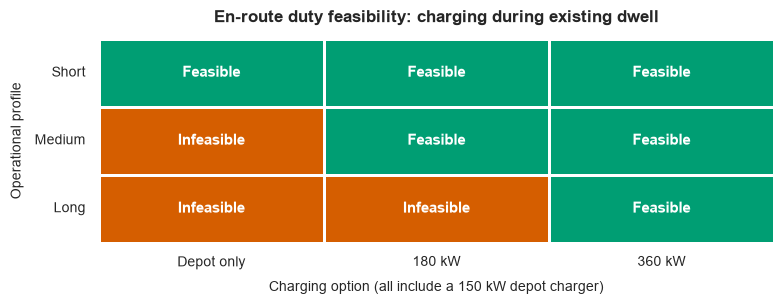

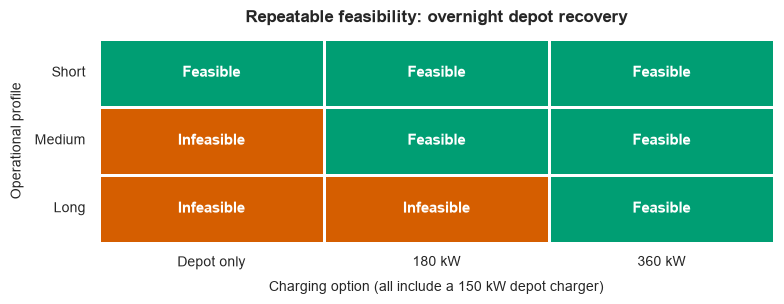

In [12]:
def plot_feasibility_matrix(matrix, title, filename):
    # Colorblind-friendly palette: Orange-Red for Infeasible, Green for Feasible
    feasibility_cmap = sns.color_palette(["#d55e00", "#009e73"], as_cmap=True)
    
    # Generate text labels
    annotations = matrix.replace({True: "Feasible", False: "Infeasible"}).to_numpy()

    fig, ax = plt.subplots(figsize=(8.0, 3.2))
    
    sns.heatmap(
        matrix.astype(int), 
        annot=annotations, 
        fmt="",
        cmap=feasibility_cmap, 
        vmin=0, vmax=1, 
        cbar=False,
        linewidths=2, 
        linecolor="white", 
        ax=ax,
        annot_kws={"weight": "bold", "size": 11, "color": "white"} # Makes text bold and clean
    )
    
    ax.set_title(title, fontsize=12, weight="bold", pad=12)
    ax.set_xlabel("Charging option (all include a 150 kW depot charger)", fontsize=10, labelpad=8)
    ax.set_ylabel("Operational profile", fontsize=10, labelpad=8)
    
    ax.tick_params(axis="y", rotation=0, labelsize=10)
    ax.tick_params(axis="x", rotation=0, labelsize=10)
    
    fig.tight_layout()
    fig.savefig(out / filename, dpi=300, bbox_inches="tight")
    plt.show()

# 1. Checks En-Route Duty Feasibility (checks if the truck completes the shift without running out of battery)
plot_feasibility_matrix(
    duty_matrix, 
    "En-route duty feasibility: charging during existing dwell", 
    "duty_feasibility_matrix.png"
)

# 2. Checks Daily Repeatable Feasibility (checks if overnight depot recovery allows a sustainable 24h cycle)
plot_feasibility_matrix(
    repeatable_matrix, 
    "Repeatable feasibility: overnight depot recovery", 
    "repeatability_matrix.png"
)

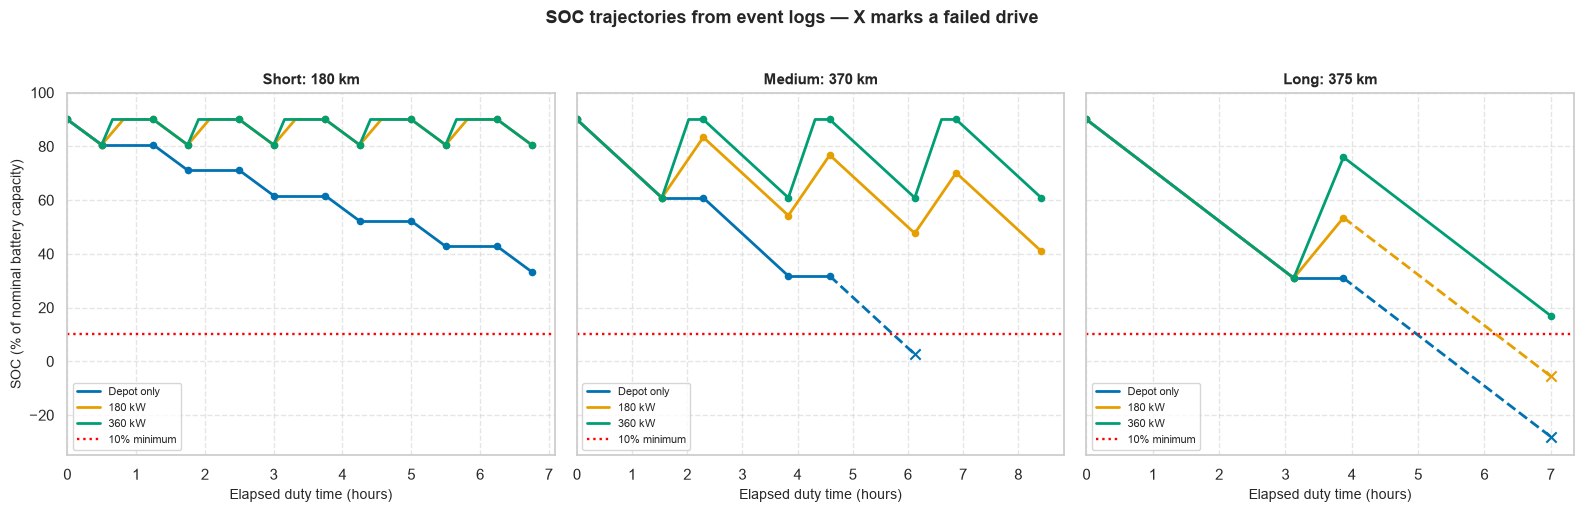

In [13]:
option_colors = {"Depot only": "#0072b2", "180 kW": "#e69f00", "360 kW": "#009e73"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, profile in zip(axes, profiles):
    for option in charging_options:
        log = event_log_df.loc[
            event_log_df["profile"].eq(profile.name)
            & event_log_df["charging_option"].eq(option.name)
        ]
        color = option_colors[option.name]
        ax.scatter([0], [truck.soc_percentage(truck.max_soc_kwh)],
                   color=color, s=20)
        for position, row in enumerate(log.to_dict("records")):
            start_h = row["start_elapsed_h"]
            end_h = row["end_elapsed_h"]
            start_soc = truck.soc_percentage(row["soc_before_kwh"])
            end_soc = row["soc_after_percent"]
            times = [start_h, end_h]
            values = [start_soc, end_soc]

            if row["grid_energy_drawn_kwh"] > TOLERANCE:
                charging_hours = row["grid_energy_drawn_kwh"] / option.opportunity_power_kw
                cap_time_h = start_h + charging_hours
                if cap_time_h < end_h - TOLERANCE:
                    times = [start_h, cap_time_h, end_h]
                    values = [start_soc, end_soc, end_soc]

            line_style = "--" if row["minimum_soc_violation"] else "-"
            ax.plot(times, values, color=color, linestyle=line_style,
                    linewidth=2, label=option.name if position == 0 else None)
            marker = "x" if row["minimum_soc_violation"] else "o"
            ax.scatter([end_h], [end_soc], color=color, marker=marker,
                       s=55 if marker == "x" else 20, zorder=4)

    ax.axhline(10, color="red", linestyle=":", linewidth=1.7,
                label="10% minimum")
    ax.set_title(f"{profile.name}: {profile.daily_distance_km():g} km", fontsize=11, weight="bold") # Added styling
    ax.set_xlabel("Elapsed duty time (hours)", fontsize=10)
    ax.set_xlim(left=0)
    ax.set_ylim(-35, 100)
    
    # Added grid for better readability
    ax.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
    
    # Deduplicated legend handles to avoid repeats
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), fontsize=8, loc="lower left")

axes[0].set_ylabel("SOC (% of nominal battery capacity)", fontsize=10)
fig.suptitle("SOC trajectories from event logs — X marks a failed drive", y=1.02, fontsize=13, weight="bold")
fig.tight_layout()
fig.savefig(out / "trajectories.png", dpi=300, bbox_inches="tight")
plt.show()


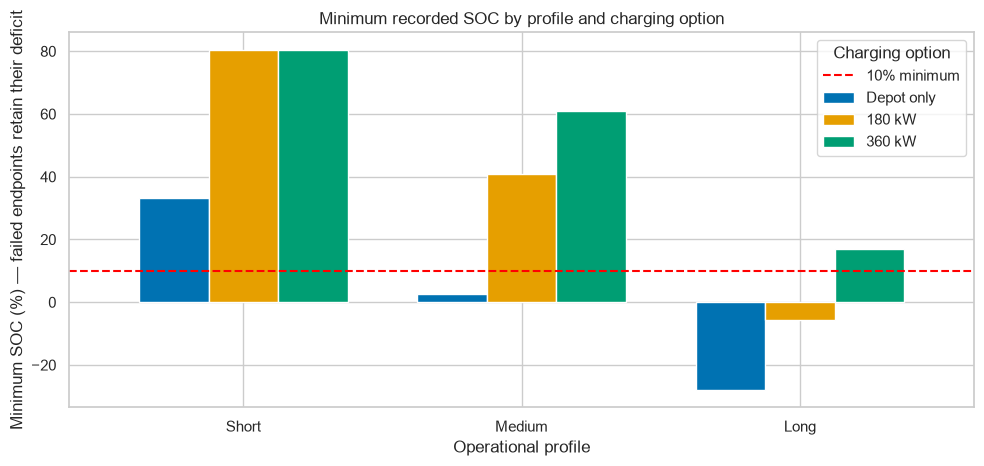

In [14]:
minimum_soc_table = summary_df.pivot(
    index="profile", columns="charging_option", values="minimum_soc_percent"
).reindex(index=profile_order, columns=option_order)

ax = minimum_soc_table.plot(
    kind="bar", figsize=(10, 4.8),
    color=[option_colors[name] for name in option_order],
    rot=0, width=0.75,
)
ax.axhline(10, color="red", linestyle="--", label="10% minimum")
ax.set_title("Minimum recorded SOC by profile and charging option")
ax.set_xlabel("Operational profile")
ax.set_ylabel("Minimum SOC (%) — failed endpoints retain their deficit")
ax.legend(title="Charging option", loc="upper right")
ax.figure.tight_layout()
ax.figure.savefig(out / "min_soc_bar.png", dpi=300, bbox_inches="tight")
plt.show()

# Sensitivity Analysis

Varying **consumption rate**

In [15]:
consumption_rates = np.linspace(0.5, 3.5, 8)

consumption_results = []

for rate in consumption_rates:
    # creating a new truck with a different consumption rate
    sensitivity_truck = Electric_Truck("Sensitivity Truck",
                                      battery_capacity_kwh=540,
                                      consumption_kwh_per_km=rate,
                                      min_soc_fraction=0.10,
                                      max_soc_fraction=0.90,
                                      charging_efficiency=0.90
                                      )
    
    # run simulation with the truck
    _, summary_sens = run_all_scenarios(
        sensitivity_truck,
        profiles,
        charging_options
    )
    
    summary_sens['consumption_kwh_per_km'] = rate
    consumption_results.append(summary_sens)
    
consumption_sensitivity_df = pd.concat(consumption_results, ignore_index=True)

consumption_sensitivity_df = consumption_sensitivity_df[["consumption_kwh_per_km",
                                                         "profile",
                                                         "charging_option",
                                                         "daily_distance_km",
                                                         "driving_energy_requirement_kwh",
                                                         "depot_grid_energy_required_kwh",
                                                         "minimum_soc_percent",
                                                         "duty_feasible",
                                                         "repeatable_daily_feasible"
                                                         ]]

display(consumption_sensitivity_df.round(2))



,consumption_kwh_per_km,profile,charging_option,daily_distance_km,driving_energy_requirement_kwh,depot_grid_energy_required_kwh,minimum_soc_percent,duty_feasible,repeatable_daily_feasible
0,0.5,Short,Depot only,180.0,90.0,100.00,73.33,True,True
1,0.5,Short,180 kW,180.0,90.0,16.67,87.22,True,True
2,0.5,Short,360 kW,180.0,90.0,16.67,87.22,True,True
3,0.5,Medium,Depot only,370.0,185.0,205.56,55.74,True,True
4,0.5,Medium,180 kW,370.0,185.0,51.39,81.44,True,True
...,...,...,...,...,...,...,...,...,...
67,3.5,Medium,180 kW,370.0,1295.0,NaN,-7.41,False,False
68,3.5,Medium,360 kW,370.0,1295.0,NaN,0.14,False,False
69,3.5,Long,Depot only,375.0,1312.5,NaN,-31.53,False,False
70,3.5,Long,180 kW,375.0,1312.5,NaN,-31.53,False,False


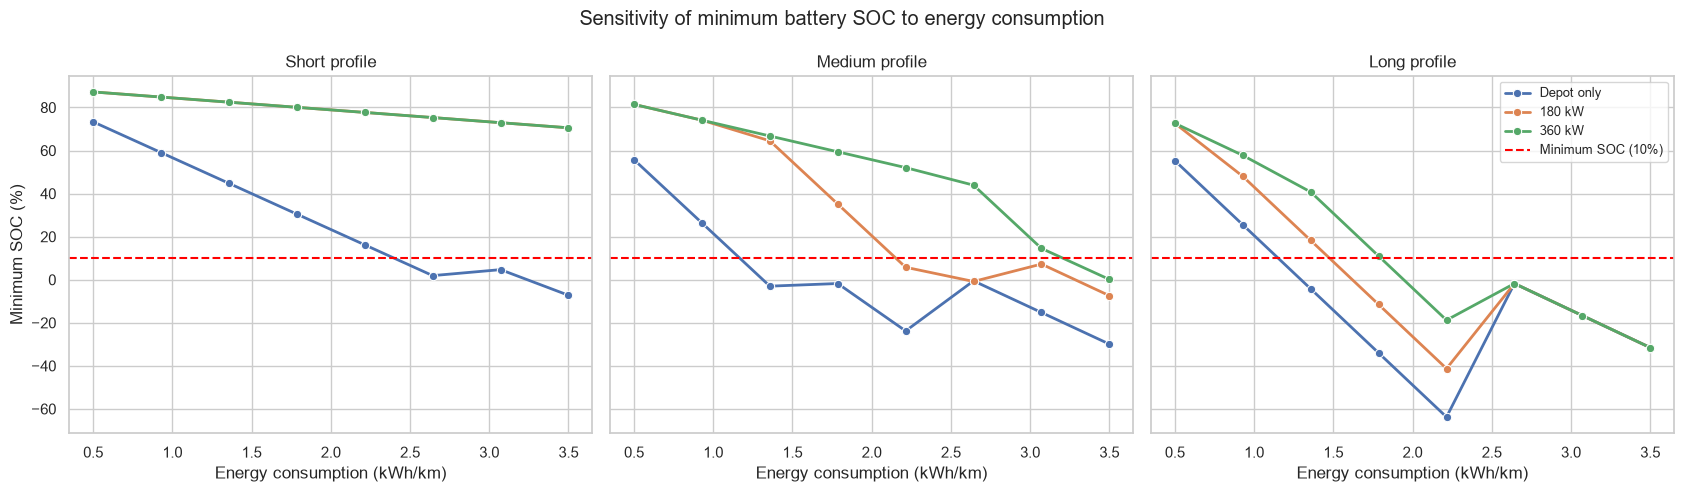

In [16]:
#Visualisation

fig, axes = plt.subplots(1, 3, figsize=(17,5), sharey=True)

for i, profile in enumerate(profiles):
    ax = axes[i]
    subset = consumption_sensitivity_df[consumption_sensitivity_df["profile"] == profile.name]
    
    sns.lineplot(
        data=subset,
        x="consumption_kwh_per_km",
        y="minimum_soc_percent",
        hue="charging_option",
        hue_order=option_order,
        marker='o',
        linewidth=2,
        ax=ax)
    
    ax.axhline(10, color="red", linestyle='--', label="Minimum SOC (10%)")
    ax.set_title(f"{profile.name} profile")
    ax.set_xlabel("Energy consumption (kWh/km)")
    ax.set_ylabel("Minimum SOC (%)")
    ax.legend()
    
    if i == len(axes) - 1:
        ax.legend(loc="upper right", fontsize=9)
    else:
        legend = ax.get_legend()
        if legend:
            legend.remove()
    
fig.suptitle("Sensitivity of minimum battery SOC to energy consumption")
fig.tight_layout()
fig.savefig(out/"consumption_sensitivity_soc.png", dpi=300, bbox_inches="tight")

plt.show()

Varying **dwell times**

In [17]:
dwell_times = [0.25, 0.50, 0.75, 1.00, 1.25, 1.50]
dwell_results = []

# testing destination dwell and port dwell individually
dwell_features = ["Destination", "Port Terminal"]

for feature in dwell_features:
    for time in dwell_times:
        #create a new operation profile with the new dwell times
        profiles_new = []
        for profile in profiles:
            destination_dwell = profile.destination_dwell_h
            port_dwell = profile.port_dwell_h

            if feature == "Destination":
                destination_dwell = time
            else:
                port_dwell = time
            
            modified_profile = Operational_Profile(
                name=profile.name,
                one_way_distance_km=profile.one_way_distance_km,
                round_trips=profile.round_trips,
                average_speed_kmh=profile.average_speed_kmh,
                destination_dwell_h=destination_dwell,
                port_dwell_h=port_dwell,
                duty_start_hour=profile.duty_start_hour
            )
            profiles_new.append(modified_profile)
    
        # run simulation with the new profile
        _,    summary_sens1 = run_all_scenarios(
            truck,
            profiles_new,
            charging_options
        )
    
        summary_sens1['sensitivity_parameter'] = feature
        summary_sens1['dwell_time_h'] = time

        dwell_results.append(summary_sens1)

dwell_sensitivity_df = pd.concat(dwell_results, ignore_index=True)
dwell_sensitivity_df = dwell_sensitivity_df[["sensitivity_parameter", "dwell_time_h", 
                                             #"destination_dwell_h", "port_dwell_h",
                                                         "profile",
                                                         "charging_option",
                                                         "duty_duration_h",
                                                         "minimum_soc_percent",
                                                         #"opportunity_grid_energy_kwh",
                                                         #"depot_grid_energy_required_kwh",
                                                         "duty_feasible",
                                                         "repeatable_daily_feasible"
                                                         ]]

display(dwell_sensitivity_df.round(2))



,sensitivity_parameter,dwell_time_h,profile,charging_option,duty_duration_h,minimum_soc_percent,duty_feasible,repeatable_daily_feasible
0,Destination,0.25,Short,Depot only,5.25,33.33,True,True
1,Destination,0.25,Short,180 kW,5.25,78.61,True,True
2,Destination,0.25,Short,360 kW,5.25,80.56,True,True
3,Destination,0.25,Medium,Depot only,7.42,2.64,False,False
4,Destination,0.25,Medium,180 kW,7.42,11.02,True,True
...,...,...,...,...,...,...,...,...
103,Port Terminal,1.50,Medium,180 kW,9.17,54.26,True,True
104,Port Terminal,1.50,Medium,360 kW,9.17,60.88,True,True
105,Port Terminal,1.50,Long,Depot only,7.00,-28.06,False,False
106,Port Terminal,1.50,Long,180 kW,7.00,-5.56,False,False


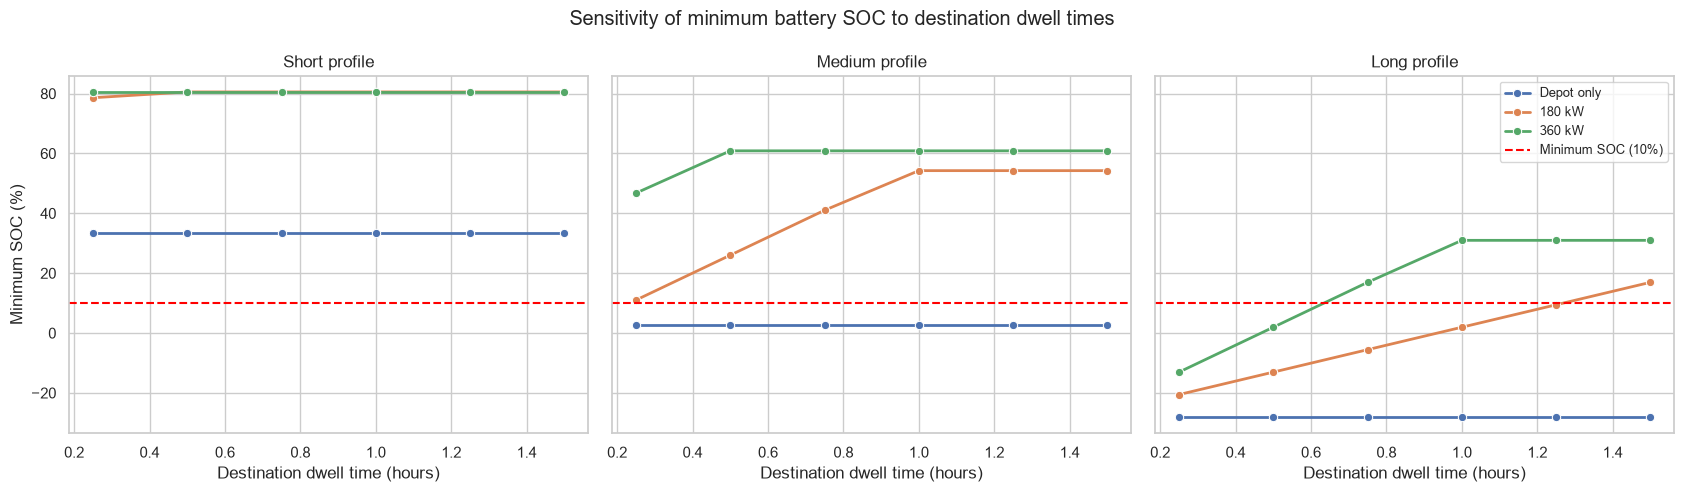

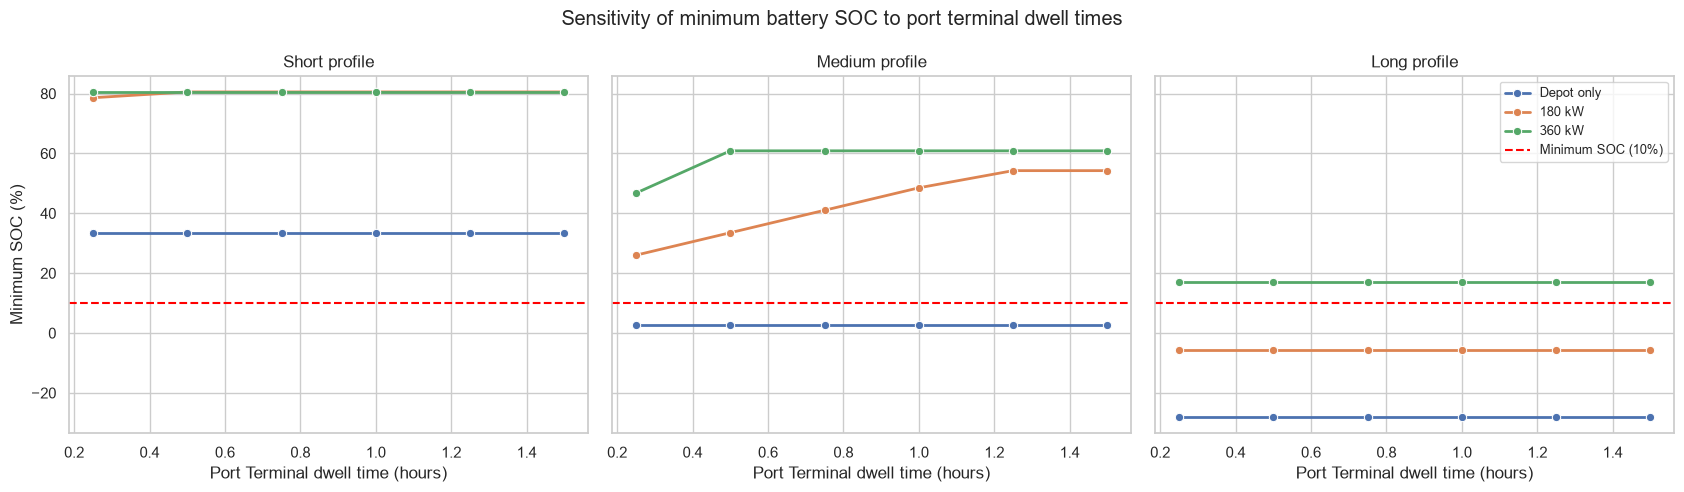

In [18]:
#Visualisation

for parameter in dwell_features:
    parameter_data = dwell_sensitivity_df[dwell_sensitivity_df["sensitivity_parameter"] == parameter]
    
    fig, axes = plt.subplots(1, 3, figsize=(17,5), sharey=True)

    for i, profile in enumerate(profiles):
        ax = axes[i]
        subset = parameter_data[parameter_data["profile"] == profile.name]
        
        sns.lineplot(
            data=subset,
            x="dwell_time_h",
            y="minimum_soc_percent",
            hue="charging_option",
            hue_order=option_order,
            marker='o',
            linewidth=2,
            ax=ax)
        
        ax.axhline(10, color="red", linestyle='--', label="Minimum SOC (10%)")
        ax.set_title(f"{profile.name} profile")
        ax.set_xlabel(f"{parameter} dwell time (hours)")
        ax.set_ylabel("Minimum SOC (%)")
        
        if i == len(axes) - 1:
            ax.legend(loc="upper right", fontsize=9)
        else:
            legend = ax.get_legend()
            if legend:
                legend.remove()
        
    fig.suptitle(f"Sensitivity of minimum battery SOC to {parameter.lower()} dwell times")
    fig.tight_layout()
    parameter_name = parameter.lower().replace(" ", "_")
    fig.savefig(out/f"{parameter_name}_dwell_sensitivity_soc.png", dpi=300, bbox_inches="tight")

    plt.show()

## Simplified Maasvlakte terminal charging demand

**EXTREME ALL-VEHICLES SCENARIO:** every counted inbound `anyVehicle` crossing is treated as an electric truck visiting the modelled terminal. This is an assumption, not a measured truck count. The data category `RWS01_MONIBAS_0151hrl0248ra` is treated as inbound travel toward Maasvlakte based on Dexter data.

The traffic input is a representative high flow day throughout the year: for each local clock hour 00–23, it takes the highest valid inbound flow found anywhere in the supplied dataset across the year. Its 24 maxima may come from different dates. This is based on `gem_intensiteit` and designs for worst-case demand scenario.

In every hour, including nighttime, the inbound arrivals are allocated as 70% short, 20% medium and 10% long visits. This is a simplifcation based on the Smart Freigth Center assumptions. These are fixed visit shares across the hours of the day, even though a more realistic assumption would be to understand the more likely shares of operational profiles across each hour. This was not possible because no data on actual truck duties and start-finish times could be found.

The following grid electricity per visit are assumed:

| Visit group | Assumed terminal charging | Grid kWh per visit |
|---|---|---:|
| Short | None | 0 |
| Medium | Full 45 minutes at 180 kW | 135 |
| Long | Full 45 minutes at 360 kW | 270 |

The calculation is:

`total_terminal_kwh = inbound_flow × (0.20 × 135 + 0.10 × 270) = inbound_flow × 54`

Short operational profile visits never generate charging need according to the algorithm results above.

Energy is associated with arrival hour. We do not develop a detailed charging schedule.

In [24]:

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Configuration & Constants
demand_data_folder = Path("dexter_data")
if not demand_data_folder.is_dir():
    demand_data_folder = Path("Project") / "dexter_data"

INBOUND_COUNTER = "RWS01_MONIBAS_0151hrl0248ra"  # provisional direction toward Maasvlakte
MIN_VALID_MINUTES = 55
MEDIUM_GRID_KWH_PER_VISIT = 180 * (45 / 60)    # full dwell at rated power: 135 grid kWh
LONG_GRID_KWH_PER_VISIT = 360 * (45 / 60)      # full dwell at rated power: 270 grid kWh

# 2. Load Raw Traffic Data
# (Adjust filename to 'intensiteit-snelheid-export.csv' or your specific path)
traffic_raw = pd.read_csv('Data final/intensiteit-snelheid-export.csv')

# 3. Type Conversion & Cleaning
numeric_cols = [
    'gem_intensiteit', 'gem_snelheid', 'gewogen_gem_snelheid', 
    'data_error_intensiteit', 'data_error_snelheid', 
    'gebruikte_minuten_intensiteit', 'gebruikte_minuten_snelheid'
]

for col in numeric_cols:
    if col in traffic_raw.columns:
        traffic_raw[col] = pd.to_numeric(traffic_raw[col], errors='coerce')

traffic_raw['start_meetperiode'] = pd.to_datetime(traffic_raw['start_meetperiode'])
traffic_raw['eind_meetperiode'] = pd.to_datetime(traffic_raw['eind_meetperiode'])

# 4. Filter Inbound Rows
inbound_rows = traffic_raw.loc[
    traffic_raw["id_meetlocatie"].eq(INBOUND_COUNTER)
    & traffic_raw["voertuigcategorie"].eq("anyVehicle")
].copy()

if set(inbound_rows["rijstrook_rijbaan"].unique()) != {"lane1", "lane2"}:
    raise ValueError("Expected two distinct inbound lanes; inspect the supplied export.")

# 5. Lane Validation & Flow Processing
duplicate_lane_time = inbound_rows.duplicated(
    ["start_meetperiode", "rijstrook_rijbaan"], keep=False
)
interval_hours = (
    inbound_rows["eind_meetperiode"] - inbound_rows["start_meetperiode"]
).dt.total_seconds() / 3600

has_exclusion = pd.Series(False, index=inbound_rows.index)
for column in ["technical_exclusion", "traffic_flow_deviation_exclusions"]:
    if column in inbound_rows.columns:
        has_exclusion |= inbound_rows[column].fillna("").astype(str).str.strip().ne("")

valid_lane = (
    inbound_rows["data_error_intensiteit"].eq(0)
    & inbound_rows["gebruikte_minuten_intensiteit"].ge(MIN_VALID_MINUTES)
    & inbound_rows["gem_intensiteit"].ge(0)
    & np.isclose(interval_hours, 1)
    & ~duplicate_lane_time
    & ~has_exclusion
)
inbound_rows["valid_flow"] = inbound_rows["gem_intensiteit"].where(valid_lane)

# 6. Aggregate by Hour and Synthesize Composite High-Flow Day
inbound_hours = inbound_rows.groupby("start_meetperiode").agg(
    lane_rows=("rijstrook_rijbaan", "size"),
    valid_lanes=("valid_flow", "count"),
    inbound_flow=("valid_flow", lambda values: values.sum(min_count=2)),
    mean_speed=("gem_snelheid", "mean")
).reset_index()

complete_hour = inbound_hours["lane_rows"].eq(2) & inbound_hours["valid_lanes"].eq(2)
valid_inbound_hours = inbound_hours.loc[complete_hour].copy()
valid_inbound_hours["hour"] = valid_inbound_hours["start_meetperiode"].dt.hour

maximum_indices = valid_inbound_hours.groupby("hour")["inbound_flow"].idxmax()
composite_high_flow_day = valid_inbound_hours.loc[
    maximum_indices, ["hour", "start_meetperiode", "inbound_flow", "mean_speed"]
].sort_values("hour").reset_index(drop=True)

if composite_high_flow_day["hour"].tolist() != list(range(24)):
    raise ValueError("At least one clock hour has no valid inbound observation.")

# 7. Final Output Summary Table for Simulation
hourly_summary = composite_high_flow_day.rename(columns={"mean_speed": "gem_snelheid"})

print("Valid complete inbound road hours:", len(valid_inbound_hours))
print("Rejected inbound lane records:", int((~valid_lane).sum()))
print("Composite high-flow day: successfully synthesized 24 representative hours.")


Valid complete inbound road hours: 8694
Rejected inbound lane records: 132
Composite high-flow day: successfully synthesized 24 representative hours.


### Hourly visits and terminal electricity

Multiply the same three visit shares into **every** hourly inbound flow. Expected visit counts may be fractional. Medium and long electricity use the fixed 135 and 270 grid-kWh amounts above. Short terminal electricity stays zero; no charging-efficiency correction is applied to these already-grid-side amounts.

In [25]:
hourly_terminal_demand = composite_high_flow_day[["hour", "inbound_flow"]].copy()

# The same visit shares apply to all 24 rows, including nighttime.
hourly_terminal_demand["short_visits"] = hourly_terminal_demand["inbound_flow"] * 0.70
hourly_terminal_demand["medium_visits"] = hourly_terminal_demand["inbound_flow"] * 0.20
hourly_terminal_demand["long_visits"] = hourly_terminal_demand["inbound_flow"] * 0.10

# These are assumed full-dwell grid amounts per visit, independent of the earlier SOC model.
hourly_terminal_demand["short_terminal_kwh"] = 0.0
hourly_terminal_demand["medium_terminal_kwh"] = (
    hourly_terminal_demand["medium_visits"] * MEDIUM_GRID_KWH_PER_VISIT
)
hourly_terminal_demand["long_terminal_kwh"] = (
    hourly_terminal_demand["long_visits"] * LONG_GRID_KWH_PER_VISIT
)
hourly_terminal_demand["total_terminal_kwh"] = (
    hourly_terminal_demand["medium_terminal_kwh"]
    + hourly_terminal_demand["long_terminal_kwh"]
)

# Check the visit split, zero short charging and the requested 54-kWh-per-crossing identity.
assert np.allclose(
    hourly_terminal_demand[["short_visits", "medium_visits", "long_visits"]].sum(axis=1),
    hourly_terminal_demand["inbound_flow"],
)
assert np.allclose(hourly_terminal_demand["short_terminal_kwh"], 0)
assert np.allclose(
    hourly_terminal_demand["total_terminal_kwh"],
    54 * hourly_terminal_demand["inbound_flow"],
)

print("EXTREME SCENARIO: every counted inbound anyVehicle crossing is an electric terminal truck.")
print("Not measured truck demand or an installation recommendation. Inbound direction is provisional.")
display(hourly_terminal_demand[[
    "hour", "inbound_flow", "short_visits", "medium_visits", "long_visits",
    "medium_terminal_kwh", "long_terminal_kwh", "total_terminal_kwh",
]])
composite_total_inbound = hourly_terminal_demand["inbound_flow"].sum()
composite_total_terminal_kwh = hourly_terminal_demand["total_terminal_kwh"].sum()
print(f"Composite day inbound flow: {composite_total_inbound:,.0f} vehicle-count equivalents")
print(f"Composite day terminal grid electricity: {composite_total_terminal_kwh:,.0f} kWh")
print("All hourly checks passed.")

EXTREME SCENARIO: every counted inbound anyVehicle crossing is an electric terminal truck.
Not measured truck demand or an installation recommendation. Inbound direction is provisional.


,hour,inbound_flow,short_visits,medium_visits,long_visits,medium_terminal_kwh,long_terminal_kwh,total_terminal_kwh
0,0,107.0,74.9,21.4,10.7,2889.0,2889.0,5778.0
1,1,91.0,63.7,18.2,9.1,2457.0,2457.0,4914.0
2,2,122.0,85.4,24.4,12.2,3294.0,3294.0,6588.0
3,3,311.0,217.7,62.2,31.1,8397.0,8397.0,16794.0
4,4,541.0,378.7,108.2,54.1,14607.0,14607.0,29214.0
5,5,1592.0,1114.4,318.4,159.2,42984.0,42984.0,85968.0
6,6,3883.0,2718.1,776.6,388.3,104841.0,104841.0,209682.0
7,7,2798.0,1958.6,559.6,279.8,75546.0,75546.0,151092.0
8,8,1687.0,1180.9,337.4,168.7,45549.0,45549.0,91098.0
9,9,1576.0,1103.2,315.2,157.6,42552.0,42552.0,85104.0


Composite day inbound flow: 24,365 vehicle-count equivalents
Composite day terminal grid electricity: 1,315,710 kWh
All hourly checks passed.


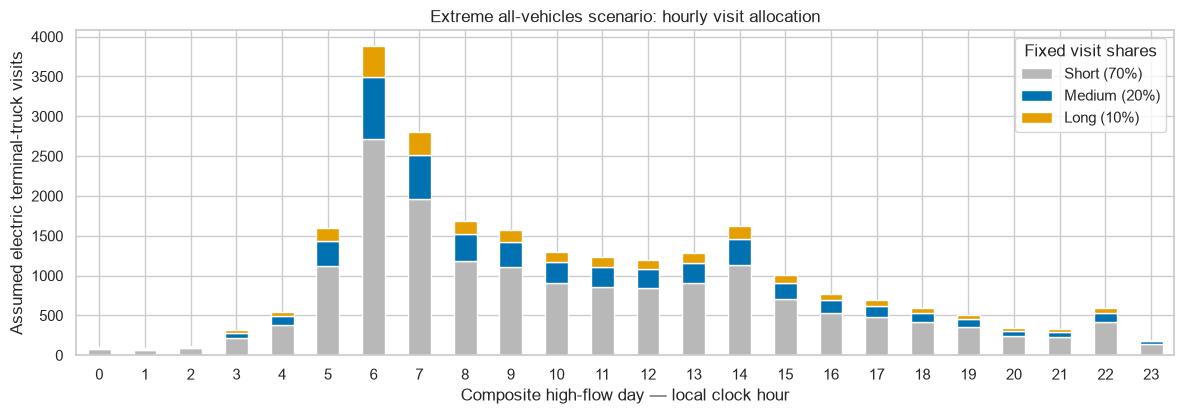

In [ ]:
# Stack the three visit groups so their combined height equals the hourly inbound flow
visit_plot = hourly_terminal_demand.set_index("hour")[[
    "short_visits", "medium_visits", "long_visits"
]].rename(columns={
    "short_visits": "Short (70%)", "medium_visits": "Medium (20%)", "long_visits": "Long (10%)"
})
ax = visit_plot.plot(
    kind="bar", stacked=True, figsize=(12, 4.3),
    color=["#b8b8b8", "#0072b2", "#e69f00"], rot=0,
)
ax.set_title("Extreme all-vehicles scenario: hourly visit allocation")
ax.set_xlabel("Composite high-flow day — local clock hour")
ax.set_ylabel("Assumed electric terminal-truck visits")
ax.legend(title="Fixed visit shares")
ax.figure.tight_layout()
plt.show()
fig.savefig(out/f"{parameter_name}_extreme_scenario_hourly_visit.png", dpi=300, bbox_inches="tight")

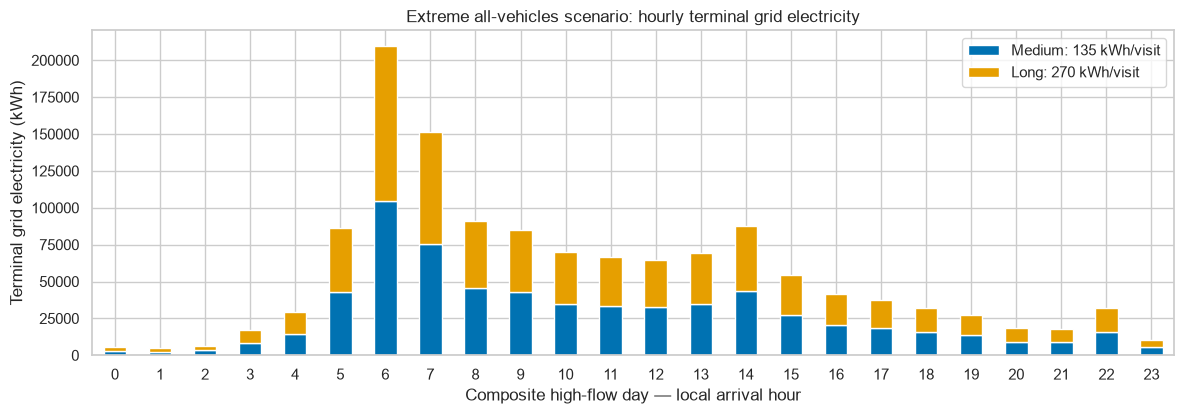

In [30]:
# Stack only Medium and Long electricity; Short visits contribute zero terminal kWh.
energy_plot = hourly_terminal_demand.set_index("hour")[[
    "medium_terminal_kwh", "long_terminal_kwh"
]].rename(columns={
    "medium_terminal_kwh": "Medium: 135 kWh/visit",
    "long_terminal_kwh": "Long: 270 kWh/visit",
})
ax = energy_plot.plot(
    kind="bar", stacked=True, figsize=(12, 4.3),
    color=["#0072b2", "#e69f00"], rot=0,
)
ax.set_title("Extreme all-vehicles scenario: hourly terminal grid electricity")
ax.set_xlabel("Composite high-flow day — local arrival hour")
ax.set_ylabel("Terminal grid electricity (kWh)")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.legend()
ax.figure.tight_layout()
plt.show()
fig.savefig(out/f"{parameter_name}_extreme_scenario_hourly_term_grid_electricity.png", dpi=300, bbox_inches="tight")

### Interpretation

The terminal total is **54 grid kWh per inbound vehicle-count equivalent** because every hour uses the same visit shares and full-dwell charging amounts. The composite day combines hourly maxima that may come from different dates, and every `anyVehicle` crossing is assumed to be an electric truck visiting this terminal. This extreme scenario is **not measured truck demand or an installation recommendation**. The inbound direction assignment still needs verification. The original duty feasibility analysis remains available separately; it does not determine or limit these fixed per-visit charging assumptions.